In [ ]:
#METODE ELBOW UNTUK K-MEANS#
# Pastikan semua library yang dibutuhkan sudah diinstal
# Jika belum diinstal, jalankan: !pip install pandas scikit-learn matplotlib openpyxl
import pandas as pd
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt


In [ ]:
# Load data dari file Excel yang diunggah (gantilah 'file.xlsx' dengan nama file yang diunggah)
file_path = '/content/VARIABEL MAGANG.xlsx'
df = pd.read_excel(file_path, sheet_name='var_fix')

In [ ]:
# Menampilkan beberapa baris pertama untuk memastikan data terbaca dengan benar
print(df.head())
# Memproses data untuk clustering
# ---CHANGE START---
# Select only numerical columns for clustering
X = df.select_dtypes(include=['number'])
# ---CHANGE END---
# Menentukan jumlah cluster optimal menggunakan metode Elbow
inertia = []
K = range(1, 11)
for k in K:
  kmeans = KMeans(n_clusters=k, random_state=42)
  kmeans.fit(X)
  inertia.append(kmeans.inertia_)

     Kab/Kota      X1    X2        X3       X4        X5        X6       X7
0   Bangkalan   49214  0.58  215098.2   878.44  21722.65  5340.014  1963.99
1  Banyuwangi   85051  0.70  525184.9  1145.35  21449.16  4618.797  2156.29
2      Blitar   46911  0.60  277420.8  1223.45  20576.48  4817.858  1905.18
3  Bojonegoro  112791  0.59  815274.1  1078.46  20406.68  4487.209  1941.68
4   Bondowoso   58121  0.60  286144.9  1138.38  21972.47  4613.547  1875.85


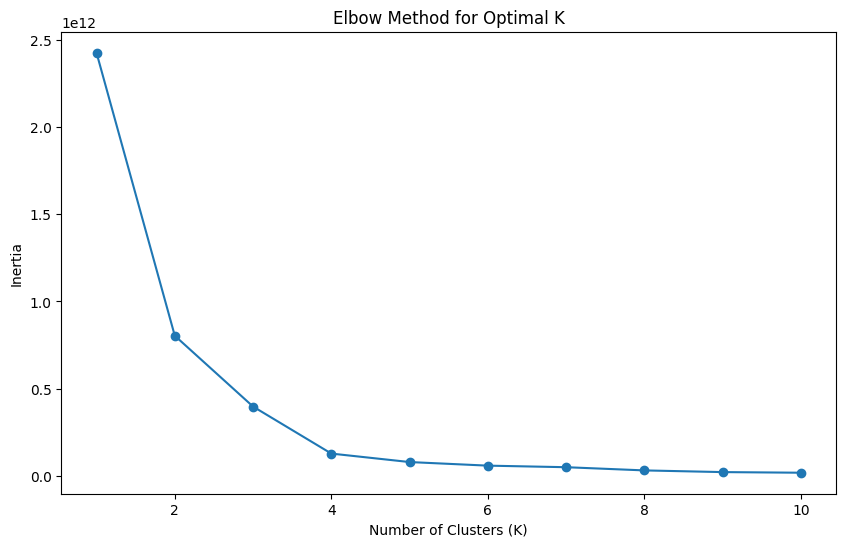

In [ ]:
# Plot metode Elbow
plt.figure(figsize=(10, 6))
plt.plot(K, inertia, marker='o')
plt.xlabel('Number of Clusters (K)')
plt.ylabel('Inertia')
plt.title('Elbow Method for Optimal K')
plt.show()

In [ ]:
#Centroid K-MEANS#
import pandas as pd
from sklearn.cluster import KMeans
import matplotlib.pyplot as plt

In [ ]:
# Menjalankan algoritma K-Means dengan jumlah cluster optimal (K = 4)
kmeans = KMeans(n_clusters=4, random_state=42)
# Select only numerical features for clustering
X = df.select_dtypes(include=['number'])
kmeans.fit(X) # Fit the model with numerical data only.
# Menambahkan label cluster ke data
df['Cluster'] = kmeans.labels_
# Menampilkan centroid dari setiap cluster
# Select columns for centroids excluding the 'Cluster' column
centroids = pd.DataFrame(kmeans.cluster_centers_, columns=X.columns)
# Kolom terakhir diabaikan karena label cluster
print("Centroid dari masing-masing cluster:")
print(centroids)

Centroid dari masing-masing cluster:
              X1        X2             X3           X4            X5  \
0    8789.666667  0.575833   37002.366667  1012.366667  11477.935608   
1   79445.714286  0.544286  489898.914286  1060.460000  20996.092857   
2   51883.133333  0.666667  266693.313333  1099.359333  20190.108800   
3  138131.750000  0.572500  835135.650000  1026.100000  20845.822500   

            X6           X7  
0  4093.177137  2074.811667  
1  4543.673714  2014.552857  
2  4726.734200  2076.077333  
3  4502.539250  1986.675000  


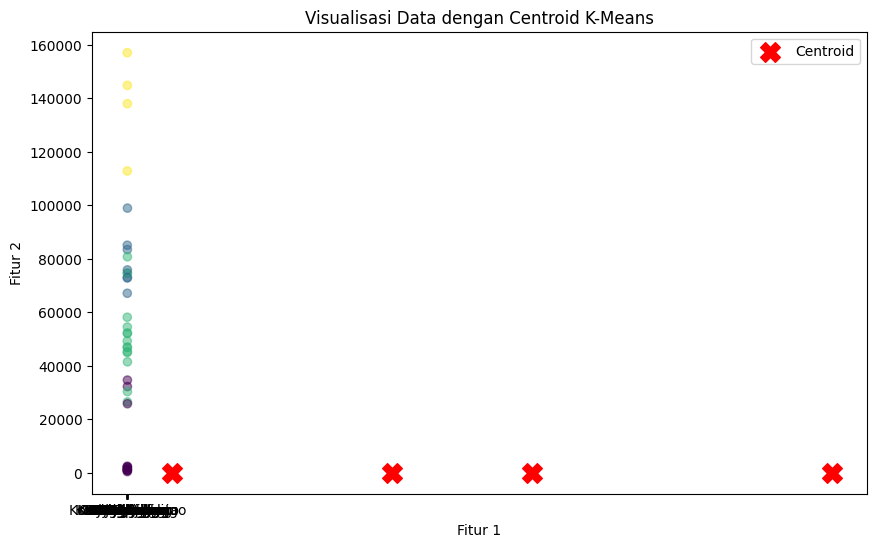

In [ ]:
# Visualisasi centroid (opsional)
plt.figure(figsize=(10, 6))
plt.scatter(df.iloc[:, 0], df.iloc[:, 1], c=df['Cluster'], cmap='viridis', marker='o', alpha=0.5)
plt.scatter(centroids.iloc[:, 0], centroids.iloc[:, 1], c='red', marker='X', s=200,
label='Centroid')
plt.xlabel('Fitur 1')
plt.ylabel('Fitur 2')
plt.title('Visualisasi Data dengan Centroid K-Means')
plt.legend()
plt.show()

In [ ]:
# Jarak Euclidean K-Means
import pandas as pd
from sklearn.cluster import KMeans
from scipy.spatial.distance import cdist
from sklearn.metrics import silhouette_score

In [ ]:
# Jarak Euclidean K-Means
import pandas as pd
from sklearn.cluster import KMeans
from scipy.spatial.distance import cdist
from sklearn.metrics import silhouette_score

# Asumsi kolom pertama adalah nama kabupaten/kota dan mulai dari kolom kedua adalah data numerik
kota = df['Kab/Kota'] # Mengambil nama kabupaten/kota
data = df.iloc[:, 2:] # Mengambil kolom data numerik
# Menentukan jumlah cluster (K = 3) dan menjalankan K-Means
kmeans = KMeans(n_clusters=4, random_state=42)
kmeans.fit(data)
# Menghitung jarak Euclidean dari setiap kabupaten/kota ke setiap centroid cluster
distances = cdist(data, kmeans.cluster_centers_, 'euclidean')
# Change the range to 4 to match the number of clusters
distance_df = pd.DataFrame(distances, columns=[f'Klaster {i+1}' for i in range(4)])
distance_df.insert(0, 'Kabupaten/Kota', kota)
# Menentukan cluster berdasarkan jarak minimum
distance_df['Cluster'] = distance_df.iloc[:, 1:].idxmin(axis=1)
# Menambahkan nomor urut seperti yang ada di contoh
distance_df.insert(0, 'No', range(1, len(distance_df) + 1))
# Menampilkan tabel jarak Euclidean dan keanggotaan cluster
print("Tabel Jarak Euclidean dan Keanggotaan Cluster:")
print(distance_df)


Tabel Jarak Euclidean dan Keanggotaan Cluster:
    No    Kabupaten/Kota      Klaster 1      Klaster 2      Klaster 3  \
0    1         Bangkalan  178394.688395  274802.893551   51622.106538   
1    2        Banyuwangi  488284.662639   35289.360959  258494.691992   
2    3            Blitar  240591.781019  212478.796193   10736.906483   
3    4        Bojonegoro  778323.063223  325375.733135  548580.898570   
4    5         Bondowoso  249364.118152  203756.427735   19534.468517   
5    6            Gresik  445156.784205    7853.883058  215371.607997   
6    7            Jember  675293.932053  222321.767062  445528.722990   
7    8           Jombang  363709.892720   89315.707639  133893.840912   
8    9            Kediri  175216.699512  277946.857333   54749.079076   
9   10         Kota Batu   31571.148211  484325.754115  261139.586730   
10  11       Kota Blitar   30703.083608  483544.455770  260438.718968   
11  12       Kota Kediri   29482.979917  480774.042465  257876.701051   
12  

In [ ]:
distance_df.to_excel("E:\magang\Kominfo\membership K-Means.xlsx", index=False)

In [ ]:
# Menghitung Silhouette Index
labels = kmeans.labels_ # Label klaster dari hasil K-Means
silhouette_avg = silhouette_score(data, labels)
print(f"\nSilhouette Index untuk hasil clustering: {silhouette_avg:.4f}")
# Jika ingin menyimpan hasilnya ke dalam file Excel
# distance_df.to_excel('Hasil_Cluster_Jarak_Euclidean.xlsx', index=False)



Silhouette Index untuk hasil clustering: 0.6524
